# 06 — Probabilidade Condicional e Teorema de Bayes

No problema de Monty Hall (notebook 05), a porta aberta pelo apresentador **mudou as chances**. Toda vez que recebemos uma informação nova, as probabilidades devem ser atualizadas. A ferramenta para isso é a **probabilidade condicional**, e a regra para "virá-la do avesso" é o **Teorema de Bayes**.

Este é provavelmente o notebook mais importante da Parte II para o ML:
- A **precisão** e o **recall** do ML-02 são probabilidades condicionais.
- O classificador **Naive Bayes** é o Teorema de Bayes aplicado diretamente.
- A **taxa base** (a proporção de cada classe) explica por que classes raras são difíceis.

Neste notebook vamos:
- Definir a **probabilidade condicional** e calculá-la a partir de tabelas
- Entender **independência**
- Usar a **regra do produto** e a **lei da probabilidade total**
- Deduzir e aplicar o **Teorema de Bayes** no exemplo do exame médico
- Construir um pequeno **Naive Bayes à mão** com os pinguins

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: probabilidade condicional

$P(A \mid B)$ (lê-se "probabilidade de A **dado** B") é a probabilidade de $A$ quando **já sabemos** que $B$ aconteceu:

$$P(A \mid B) = \frac{P(A \text{ e } B)}{P(B)}$$

A ideia: saber que $B$ aconteceu **encolhe o espaço amostral** para $B$. Dentro desse mundo menor, perguntamos que fração também é $A$.

Analogia: a chance de uma pessoa qualquer estar de guarda-chuva é baixa. Mas **dado** que está chovendo, ela é bem maior. A chuva não muda as pessoas, só muda **o grupo** que estamos olhando.

**Atenção:** $P(A \mid B)$ e $P(B \mid A)$ são coisas **diferentes**. A chance de um jogador da NBA ser alto é quase 100%; a chance de uma pessoa alta ser jogador da NBA é minúscula. Confundir as duas é um dos erros mais comuns (e mais caros) do raciocínio com probabilidades.

In [2]:
# Tabela de contingência do notebook 04: dia × fumantes.
tabela = pd.crosstab(gorjetas["day"], gorjetas["smoker"], margins=True)
print(tabela, "\n")

n = len(gorjetas)
# P(fumante e sexta) e P(sexta): contagens divididas pelo total de mesas.
p_fumante_e_sexta = tabela.loc["Fri", "Yes"] / n     # .loc[linha, coluna] acessa uma célula pelos rótulos
p_sexta = tabela.loc["Fri", "All"] / n
p_fumante = tabela.loc["All", "Yes"] / n

print(f"P(fumante)            = {p_fumante:.4f}")
print(f"P(fumante | sexta)    = {p_fumante_e_sexta / p_sexta:.4f}   (pela fórmula)")
print(f"                      = {tabela.loc['Fri', 'Yes']} / {tabela.loc['Fri', 'All']}  (contando só as mesas de sexta)")
# A ordem inversa: entre as mesas com fumantes, que fração é de sexta?
print(f"P(sexta | fumante)    = {p_fumante_e_sexta / p_fumante:.4f}")

smoker  Yes   No  All
day                  
Thur     17   45   62
Fri      15    4   19
Sat      42   45   87
Sun      19   57   76
All      93  151  244 

P(fumante)            = 0.3811
P(fumante | sexta)    = 0.7895   (pela fórmula)
                      = 15 / 19  (contando só as mesas de sexta)
P(sexta | fumante)    = 0.1613


**Conclusão:** no geral, **38,1%** das mesas têm fumantes. Mas, **dado** que a mesa é de sexta-feira, a chance sobe para **78,9%** (15 das 19 mesas). A fórmula e a contagem direta dão o mesmo resultado: condicionar é simplesmente olhar **só para as linhas da sexta**.

A ordem inversa é bem diferente: entre as mesas com fumantes, só **16,1%** são de sexta. A sexta tem muitos fumantes, mas é um dia com poucas mesas, então ela representa uma parte pequena dos fumantes. É o exemplo do jogador da NBA com os nossos dados: $P(\text{fumante} \mid \text{sexta}) \neq P(\text{sexta} \mid \text{fumante})$.

## 🎓 Conceito: independência

Dois eventos são **independentes** quando saber de um **não muda** a probabilidade do outro:

$$P(A \mid B) = P(A) \quad \Longleftrightarrow \quad P(A \text{ e } B) = P(A) \cdot P(B)$$

Exemplo: os resultados de dois dados são independentes; saber que o primeiro deu 6 não muda nada sobre o segundo.

Na prática, com dados reais, as proporções nunca são **exatamente** iguais, mesmo quando as variáveis são independentes (lembre-se das médias de amostras do notebook 01). A pergunta "a diferença é grande demais para ser acaso?" será respondida pelo **teste do qui-quadrado** no notebook 12.

In [3]:
# Dois dados simulados: P(d2 = 6 | d1 = 6) deve ser igual a P(d2 = 6).
d1 = rng.integers(1, 7, size=1_000_000)
d2 = rng.integers(1, 7, size=1_000_000)
print(f"P(d2 = 6)            ≈ {np.mean(d2 == 6):.4f}")
print(f"P(d2 = 6 | d1 = 6)   ≈ {np.mean(d2[d1 == 6] == 6):.4f}")   # d2[d1 == 6]: só os lançamentos em que d1 deu 6
print(f"P(d1 = 6 e d2 = 6)   ≈ {np.mean((d1 == 6) & (d2 == 6)):.4f}   vs  P(d1 = 6)·P(d2 = 6) = {1/36:.4f}")

# Nos dados do tips: se dia e fumantes fossem independentes, cada célula seria P(dia) × P(fumante) × n.
observado = pd.crosstab(gorjetas["day"], gorjetas["smoker"])
p_dia = observado.sum(axis=1) / n          # soma de cada linha / n
p_fum = observado.sum(axis=0) / n          # soma de cada coluna / n
# np.outer multiplica cada P(dia) por cada P(fumante), formando a tabela "esperada sob independência".
esperado = pd.DataFrame(np.outer(p_dia, p_fum) * n, index=observado.index, columns=observado.columns)
pd.concat({"observado": observado, "esperado se independentes": esperado.round(1)}, axis=1)

P(d2 = 6)            ≈ 0.1667
P(d2 = 6 | d1 = 6)   ≈ 0.1677
P(d1 = 6 e d2 = 6)   ≈ 0.0279   vs  P(d1 = 6)·P(d2 = 6) = 0.0278


observado     esperado se independentes      
smoker       Yes  No                       Yes    No
day                                                 
Thur          17  45                      23.6  38.4
Fri           15   4                       7.2  11.8
Sat           42  45                      33.2  53.8
Sun           19  57                      29.0  47.0

**Conclusão:** nos dados simulados, saber que o primeiro dado deu 6 não muda nada: $P(d_2 = 6) \approx 0{,}1667$ e $P(d_2 = 6 \mid d_1 = 6) \approx 0{,}1677$, e a probabilidade conjunta (0,0279) é praticamente o produto (0,0278). As pequenas diferenças são ruído da simulação.

No tips, a tabela observada se afasta bastante da esperada sob independência: na sexta, esperaríamos **7,2** mesas com fumantes e há **15**; no domingo, esperaríamos **29,0** e há só **19**. Dia e fumantes **não parecem independentes**. Se essa diferença é grande o bastante para não ser acaso, o qui-quadrado do notebook 12 vai dizer.

## 🎓 Conceito: regra do produto e lei da probabilidade total

Reorganizando a definição de probabilidade condicional, temos a **regra do produto**:
$$P(A \text{ e } B) = P(A \mid B) \cdot P(B)$$

E se o espaço amostral estiver dividido em grupos que não se sobrepõem ($B_1, B_2, \dots$, como os dias da semana), a **lei da probabilidade total** diz que a probabilidade de $A$ é a **média ponderada** das probabilidades dentro de cada grupo:
$$P(A) = \sum_{i} P(A \mid B_i) \cdot P(B_i)$$

Analogia: a taxa de aprovação de uma escola é a média das taxas de cada turma, **ponderada pelo tamanho** de cada turma.

In [4]:
# P(fumante) = soma, sobre os dias, de P(fumante | dia) × P(dia)
p_fum_dado_dia = pd.crosstab(gorjetas["day"], gorjetas["smoker"], normalize="index")["Yes"]
parcelas = p_fum_dado_dia * p_dia   # multiplicação elemento a elemento, alinhada pelo dia
print(pd.DataFrame({"P(fumante | dia)": p_fum_dado_dia, "P(dia)": p_dia, "produto": parcelas}))
print(f"\nSoma das parcelas: {parcelas.sum():.4f}    P(fumante) direto: {p_fumante:.4f}")

      P(fumante | dia)  P(dia)  produto
day                                    
Thur            0.2742  0.2541   0.0697
Fri             0.7895  0.0779   0.0615
Sat             0.4828  0.3566   0.1721
Sun             0.2500  0.3115   0.0779

Soma das parcelas: 0.3811    P(fumante) direto: 0.3811


## 🎓 Conceito: Teorema de Bayes

Muitas vezes conhecemos $P(B \mid A)$, mas queremos $P(A \mid B)$. Usando a regra do produto dos dois jeitos ($P(A \text{ e } B) = P(B \mid A)\,P(A) = P(A \mid B)\,P(B)$), chegamos ao **Teorema de Bayes**:

$$P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}$$

Cada parte tem um nome:
- $P(A)$: a **priori** (*prior*), o que acreditávamos **antes** da evidência.
- $P(B \mid A)$: a **verossimilhança** (*likelihood*), quão compatível a evidência é com $A$.
- $P(A \mid B)$: a **posteriori** (*posterior*), o que passamos a acreditar **depois** da evidência.
- $P(B)$: a probabilidade total da evidência (calculada com a lei da probabilidade total).

Em palavras: **posteriori ∝ verossimilhança × priori**. Bayes é a regra para **aprender com evidências**.

## 2. O exame médico: a armadilha da taxa base

Uma doença atinge **1%** da população. Existe um exame com estas características:
- **Sensibilidade de 95%:** entre os doentes, 95% testam positivo. $P(+ \mid \text{doente}) = 0{,}95$.
- **Especificidade de 90%:** entre os saudáveis, 90% testam negativo; logo, 10% dão **falso positivo**. $P(+ \mid \text{saudável}) = 0{,}10$.

Você faz o exame e o resultado é **positivo**. Qual a chance de você ter a doença? Antes de rodar a célula, faça um palpite.

In [5]:
prevalencia = 0.01        # P(doente): a priori
sensibilidade = 0.95      # P(+ | doente)
falso_positivo = 0.10     # P(+ | saudável) = 1 - especificidade

# Lei da probabilidade total: P(+) = P(+|doente)P(doente) + P(+|saudável)P(saudável)
p_positivo = sensibilidade * prevalencia + falso_positivo * (1 - prevalencia)
# Teorema de Bayes
p_doente_dado_positivo = sensibilidade * prevalencia / p_positivo

print(f"P(+)             = {p_positivo:.4f}")
print(f"P(doente | +)    = {p_doente_dado_positivo:.4f}")

P(+)             = 0.1085
P(doente | +)    = 0.0876


In [6]:
# A mesma conta com "frequências naturais": imagine 10.000 pessoas.
pessoas = 10_000
doentes = pessoas * prevalencia
saudaveis = pessoas - doentes
tabela_exame = pd.DataFrame({
    "teste +": [doentes * sensibilidade, saudaveis * falso_positivo],
    "teste −": [doentes * (1 - sensibilidade), saudaveis * (1 - falso_positivo)],
}, index=["doentes", "saudáveis"])
tabela_exame["total"] = tabela_exame.sum(axis=1)
print(tabela_exame.round(0))

# E por simulação: sorteamos 1 milhão de pessoas e os resultados dos seus exames.
n_sim = 1_000_000
doente = rng.random(n_sim) < prevalencia                 # rng.random sorteia números entre 0 e 1
prob_positivo = np.where(doente, sensibilidade, falso_positivo)   # np.where(condição, se_sim, se_não)
positivo = rng.random(n_sim) < prob_positivo
# :_ separa os milhares com "_", que trocamos por ponto (o separador usado no Brasil).
total_positivos = f"{positivo.sum():_}".replace("_", ".")
print(f"\nSimulação: entre {total_positivos} positivos, {doente[positivo].mean():.1%} estão doentes")

           teste +  teste −   total
doentes       95.0      5.0   100.0
saudáveis    990.0   8910.0  9900.0

Simulação: entre 108.469 positivos, 8.6% estão doentes


**Conclusão:** o resultado surpreende quase todo mundo: com um exame positivo, a chance de estar doente é só **8,8%**. A tabela de 10.000 pessoas mostra por quê: dos **100** doentes, 95 testam positivo; mas dos **9.900** saudáveis, 10% (**990**) também testam positivo. Entre os 1.085 positivos, só 95 estão doentes: 95 / 1.085 = 8,8%. A simulação com 1 milhão de pessoas chega ao mesmo lugar (**8,6%**, a diferença é ruído da simulação).

Os falsos positivos são uma fração pequena de um grupo **enorme** (os saudáveis), e os verdadeiros positivos são uma fração grande de um grupo **minúsculo** (os doentes). Ignorar a taxa base (a priori) é a **falácia da taxa base**.

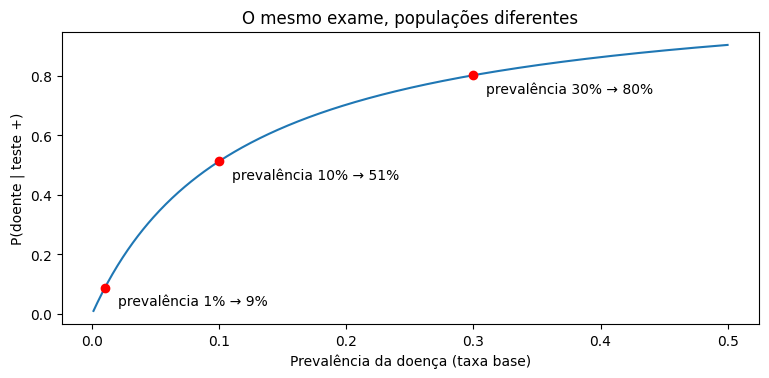

In [7]:
# Como P(doente | +) depende da prevalência (a taxa base)?
prevalencias = np.linspace(0.001, 0.5, 500)
posterior = sensibilidade * prevalencias / (sensibilidade * prevalencias + falso_positivo * (1 - prevalencias))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(prevalencias, posterior)
for p in [0.01, 0.10, 0.30]:
    valor = sensibilidade * p / (sensibilidade * p + falso_positivo * (1 - p))
    ax.scatter(p, valor, color="red", zorder=3)   # zorder=3 desenha o ponto por cima da linha
    ax.annotate(f"prevalência {p:.0%} → {valor:.0%}", xy=(p + 0.01, valor - 0.06))
ax.set_xlabel("Prevalência da doença (taxa base)")
ax.set_ylabel("P(doente | teste +)")
ax.set_title("O mesmo exame, populações diferentes")
plt.show()

**Conclusão:** o **mesmo** exame, com a mesma sensibilidade e especificidade, tem um valor muito diferente conforme a população: com prevalência de **1%**, um positivo significa **9%** de chance de doença; com **10%**, significa **51%**; e com **30%** (por exemplo, pacientes que já chegam com sintomas), **80%**. É por isso que médicos pedem exames para quem tem **sintomas** ou fatores de risco: a priori mais alta torna o resultado positivo muito mais informativo.

## 3. Atualizando com uma segunda evidência

O poder do Teorema de Bayes é que a **posteriori de hoje vira a priori de amanhã**. Se a pessoa que testou positivo fizer um **segundo exame** (independente do primeiro) e ele também der positivo, a nova priori é 8,8%, e não mais 1%.

In [8]:
def atualizar(priori, sensibilidade=0.95, falso_positivo=0.10):
    """Aplica o Teorema de Bayes para um resultado positivo."""
    return sensibilidade * priori / (sensibilidade * priori + falso_positivo * (1 - priori))


crenca = prevalencia
print(f"Antes de qualquer exame: {crenca:.1%}")
for i in range(1, 4):
    crenca = atualizar(crenca)
    print(f"Depois do {i}º positivo:   {crenca:.1%}")

Antes de qualquer exame: 1.0%
Depois do 1º positivo:   8.8%
Depois do 2º positivo:   47.7%
Depois do 3º positivo:   89.6%


**Conclusão:** cada positivo é uma evidência a mais, e a crença sobe de **1%** para **8,8%**, depois **47,7%** e **89,6%**. Nenhum exame isolado é conclusivo, mas a combinação de evidências independentes vai se acumulando. Repare que usamos sempre a **mesma** função: a única coisa que muda é a priori, que é a posteriori do passo anterior.

(A suposição de que os exames são **independentes** é importante. Se o erro vier de algo da própria pessoa, um segundo exame tende a repetir o erro, e a atualização seria exagerada. Essa mesma suposição aparece no Naive Bayes, a seguir.)

## 🎓 Conceito: o classificador Naive Bayes

Um classificador precisa calcular $P(\text{classe} \mid \text{atributos})$. Pelo Teorema de Bayes:

$$P(\text{classe} \mid x_1, x_2) \propto P(x_1, x_2 \mid \text{classe}) \cdot P(\text{classe})$$

Estimar $P(x_1, x_2 \mid \text{classe})$ exige ver **todas as combinações** de atributos, o que fica impossível com muitos atributos. O **Naive Bayes** ("Bayes ingênuo") faz uma suposição simplificadora: dentro de cada classe, os atributos são **independentes**. Assim:

$$P(x_1, x_2 \mid \text{classe}) \approx P(x_1 \mid \text{classe}) \cdot P(x_2 \mid \text{classe})$$

Cada termo é uma simples proporção numa tabela. No final, dividimos pela soma para que as probabilidades das classes somem 1.

Vamos prever a **espécie** de um pinguim a partir de duas informações: a **ilha** onde ele vive e se o **bico é longo** (mais de 45 mm).

In [9]:
pinguins["bico_longo"] = np.where(pinguins["bill_length_mm"] > 45, "sim", "não")

# Priori: a proporção de cada espécie.
priori = pinguins["species"].value_counts(normalize=True)
# Verossimilhanças: P(ilha | espécie) e P(bico_longo | espécie). normalize="index" divide cada linha (espécie) pelo seu total.
p_ilha = pd.crosstab(pinguins["species"], pinguins["island"], normalize="index")
p_bico = pd.crosstab(pinguins["species"], pinguins["bico_longo"], normalize="index")
print("Priori:\n", priori.round(3), "\n")
print("P(ilha | espécie):\n", p_ilha.round(3), "\n")
print("P(bico longo | espécie):\n", p_bico.round(3))

Priori:
 species
Adelie       0.438
Gentoo       0.357
Chinstrap    0.204
Name: proportion, dtype: float64 

P(ilha | espécie):
 island     Biscoe  Dream  Torgersen
species                            
Adelie      0.301  0.377      0.322
Chinstrap   0.000  1.000      0.000
Gentoo      1.000  0.000      0.000 

P(bico longo | espécie):
 bico_longo    não    sim
species                 
Adelie      0.979  0.021
Chinstrap   0.088  0.912
Gentoo      0.176  0.824


In [10]:
def naive_bayes(ilha, bico):
    """Probabilidade de cada espécie para um pinguim, multiplicando priori e verossimilhanças."""
    pontuacao = priori * p_ilha[ilha] * p_bico[bico]   # alinhado pela espécie
    return pontuacao / pontuacao.sum()                 # normaliza para somar 1


# Comparando com a resposta "real": a proporção de cada espécie entre os pinguins com aquela combinação exata.
casos = [("Dream", "sim"), ("Dream", "não"), ("Biscoe", "sim"), ("Torgersen", "não")]
linhas = {}
for ilha, bico in casos:
    grupo = pinguins[(pinguins["island"] == ilha) & (pinguins["bico_longo"] == bico)]
    real = grupo["species"].value_counts(normalize=True).reindex(priori.index, fill_value=0)
    linhas[(f"{ilha}, bico longo = {bico}", "Naive Bayes")] = naive_bayes(ilha, bico)
    linhas[(f"{ilha}, bico longo = {bico}", f"proporção real (n = {len(grupo)})")] = real
pd.DataFrame(linhas).T.round(3)

species                                              Adelie  Chinstrap  Gentoo
Dream, bico longo = sim     Naive Bayes               0.018      0.982   0.000
                            proporção real (n = 62)   0.000      1.000   0.000
Dream, bico longo = não     Naive Bayes               0.900      0.100   0.000
                            proporção real (n = 61)   0.902      0.098   0.000
Biscoe, bico longo = sim    Naive Bayes               0.009      0.000   0.991
                            proporção real (n = 99)   0.010      0.000   0.990
Torgersen, bico longo = não Naive Bayes               1.000      0.000   0.000
                            proporção real (n = 45)   1.000      0.000   0.000

**Conclusão:** as tabelas de verossimilhança já contam boa parte da história: os **Chinstrap** só vivem em **Dream** e os **Gentoo** só em **Biscoe**, enquanto os **Adelie** aparecem nas três ilhas; e 98% dos Adelie têm o bico **curto**, enquanto mais de 80% dos Chinstrap e dos Gentoo têm o bico longo.

Multiplicando priori e verossimilhanças, o Naive Bayes acerta muito bem as proporções reais:
- **Dream com bico longo:** 98,2% Chinstrap (real: 100%).
- **Dream com bico curto:** 90,0% Adelie (real: **90,2%**).
- **Biscoe com bico longo:** 99,1% Gentoo (real: 99,0%).
- **Torgersen com bico curto:** 100% Adelie, porque só Adelie vivem lá.

Aqui a suposição "ingênua" funciona bem porque, **dentro de cada espécie**, ilha e tamanho do bico são quase independentes. Quando os atributos repetem a mesma informação, o Naive Bayes conta a mesma evidência várias vezes e fica confiante demais. Foi o que vimos na calibração do ML-02 (notebook 06 de lá).

## 4. Resumo e próximos passos

**Conceitos que você aprendeu**
- **Probabilidade condicional** $P(A \mid B)$, e por que ela é diferente de $P(B \mid A)$.
- **Independência**: saber de um evento não muda a chance do outro.
- **Regra do produto** e **lei da probabilidade total**.
- **Teorema de Bayes**: priori, verossimilhança e posteriori; a posteriori de hoje é a priori de amanhã.
- A **armadilha da taxa base**: com uma doença rara, a maioria dos positivos é falso positivo.
- O **Naive Bayes** como Bayes + a suposição de independência condicional.

🔗 **Ponte para o ML (ML-02):**
| Neste notebook | No ML-02 |
|---|---|
| $P(+ \mid \text{doente})$ (sensibilidade) | **recall** |
| $P(\text{doente} \mid +)$ | **precisão** |
| prevalência (taxa base) | proporção da classe positiva (desbalanceamento) |
| $P(- \mid \text{saudável})$ (especificidade) | 1 − taxa de falsos positivos (curva ROC) |
| Naive Bayes à mão | `CategoricalNB` |

A armadilha da taxa base explica por que, com classes raras, a **precisão** costuma ser baixa mesmo com um bom recall.

**Python novo:** `.loc[linha, coluna]`, indexar um vetor com uma máscara de outro (`d2[d1 == 6]`), `np.outer`, `pd.concat`, `rng.random`, `np.where`, `zorder`, `.reindex`.

**Próximo notebook:** até aqui calculamos probabilidades de **eventos**. No notebook 07 vamos dar um passo além: as **variáveis aleatórias**, que associam números aos resultados (o número de caras em 10 lançamentos, o número de clientes por hora), e as primeiras **distribuições de probabilidade**: Bernoulli, binomial, Poisson e geométrica.